##Predicting Diabetes with KNN classifier

---



---





In [ ]:
from sklearn.neighbors import KNeighborsClassifier
import numpy as np
import pandas as pd
df = pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
col_list = ['Glucose',  'BloodPressure',        'SkinThickness',        'Insulin',      'BMI']
for i in col_list:
  df[i] = df[i].replace(0, np.nan)
  mean = int(df[i].mean(skipna=True))
  df[i] = df[i].replace(np.nan, mean)
  df.head()

In [ ]:

df.tail(20)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
748,3,187.0,70.0,22.0,200.0,36.4,0.408,36,1
749,6,162.0,62.0,29.0,155.0,24.3,0.178,50,1
750,4,136.0,70.0,29.0,155.0,31.2,1.182,22,1
751,1,121.0,78.0,39.0,74.0,39.0,0.261,28,0
752,3,108.0,62.0,24.0,155.0,26.0,0.223,25,0
753,0,181.0,88.0,44.0,510.0,43.3,0.222,26,1
754,8,154.0,78.0,32.0,155.0,32.4,0.443,45,1
755,1,128.0,88.0,39.0,110.0,36.5,1.057,37,1
756,7,137.0,90.0,41.0,155.0,32.0,0.391,39,0
757,0,123.0,72.0,29.0,155.0,36.3,0.258,52,1


In [ ]:
x = df.iloc[:,:8]
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,155.0,33.6,0.627,50
1,1,85.0,66.0,29.0,155.0,26.6,0.351,31
2,8,183.0,64.0,29.0,155.0,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.0,180.0,32.9,0.171,63
764,2,122.0,70.0,27.0,155.0,36.8,0.340,27
765,5,121.0,72.0,23.0,112.0,26.2,0.245,30
766,1,126.0,60.0,29.0,155.0,30.1,0.349,47


In [ ]:
y = df.iloc[:,8]
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

In [ ]:
import math
k = math.sqrt(len(x_test))
k

12.409673645990857

In [ ]:
kin = int(k)
if kin%2==0:
   kin+=1
   print(kin)


13


In [ ]:
knn = KNeighborsClassifier(n_neighbors=kin)
knn.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=13)

In [ ]:
accuracy = knn.score(x_test, y_test)
accuracy

0.7857142857142857

In [ ]:
k_range = range(1,20)
scores = []
for k in k_range:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_train, y_train)
  accuracy = knn.score(x_test, y_test)
  scores.append(accuracy)
  print('k = %d Accuracy = %.2f%%' %(k, accuracy*100))

k = 1 Accuracy = 65.58%
k = 2 Accuracy = 72.08%
k = 3 Accuracy = 72.73%
k = 4 Accuracy = 76.62%
k = 5 Accuracy = 75.32%
k = 6 Accuracy = 76.62%
k = 7 Accuracy = 75.97%
k = 8 Accuracy = 76.62%
k = 9 Accuracy = 75.32%
k = 10 Accuracy = 75.32%
k = 11 Accuracy = 75.97%
k = 12 Accuracy = 75.97%
k = 13 Accuracy = 78.57%
k = 14 Accuracy = 79.22%
k = 15 Accuracy = 77.27%
k = 16 Accuracy = 75.32%
k = 17 Accuracy = 76.62%
k = 18 Accuracy = 76.62%
k = 19 Accuracy = 78.57%


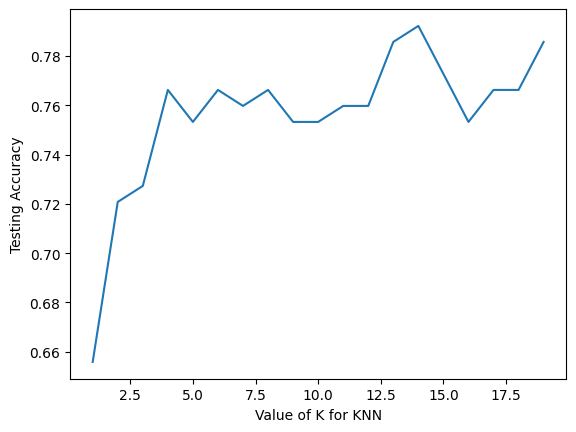

In [ ]:
import matplotlib.pyplot as plt
plt.plot(k_range, scores)
plt.xlabel('Value of K for KNN')
plt.ylabel('Testing Accuracy')
plt.show()

In [ ]:
knn = KNeighborsClassifier(n_neighbors=14 , metric = 'euclidean')
knn.fit(x_train, y_train)


KNeighborsClassifier(metric='euclidean', n_neighbors=14)

In [ ]:
accuracy = knn.score(x_test, y_test)
accuracy

0.7922077922077922

In [ ]:
knn.predict([[6,148,72,35,0,33.6,0.627,50]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([0])

In [ ]:
knn.predict([[1,189,60,23,846,30.1,0.398,59]])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([1])